# 01 - First look at the data

Quick exploration before any modelling. The questions I wanted answered:
1. Which time window is usable?
2. How much do categories and weekdays differ?
3. Is there enough price variation *within* a listing to estimate elasticities?
4. What unit should a price experiment randomise on?

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pricing.config import load_config
from pricing.data import load_items, weekly_listing_panel

cfg = load_config()
pd.set_option("display.width", 120)

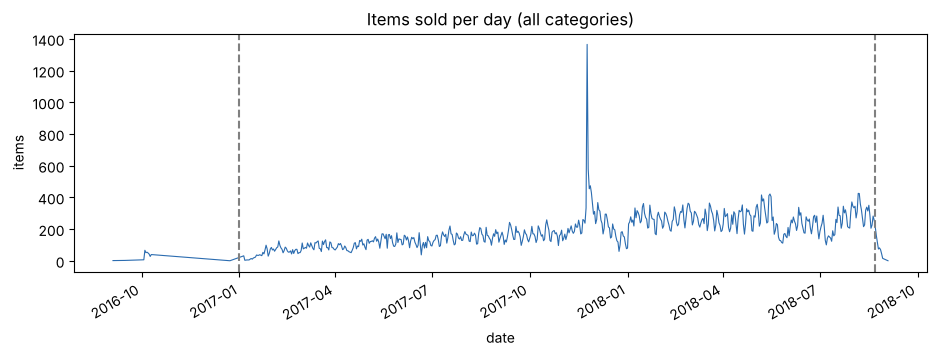

348 items before 2017
date
2018-08-20    283
2018-08-21    258
2018-08-22    216
2018-08-23    161
2018-08-24    116
2018-08-25     75
2018-08-26     82
2018-08-27     71
2018-08-28     45
2018-08-29     16
2018-09-03      1


In [2]:
# load everything first (no date filter) to see where the usable window is
all_items = load_items(cfg["data"]["raw_dir"], "2016-01-01", "2018-12-31")
daily = all_items.groupby("date").size()

fig, ax = plt.subplots(figsize=(11, 3.5))
daily.plot(ax=ax, lw=0.8, color="#2b6cb0")
ax.axvline(pd.Timestamp("2017-01-01"), color="grey", ls="--")
ax.axvline(pd.Timestamp("2018-08-22"), color="grey", ls="--")
ax.set_title("Items sold per day (all categories)")
ax.set_ylabel("items")
plt.show()

print(daily[:"2016-12-31"].sum(), "items before 2017")
print(daily["2018-08-20":].to_string())

- Almost nothing before 2017, so I start on **2017-01-01**.
- The series dies at the end of August 2018. That's the export ending, not demand, so I cut at **2018-08-22**.
- The spike in late November 2017 is Black Friday.
- There's a clear dip at the end of May 2018 (the truckers' strike in Brazil) and another in mid-July.

74 categories, top 15 = 79% of items


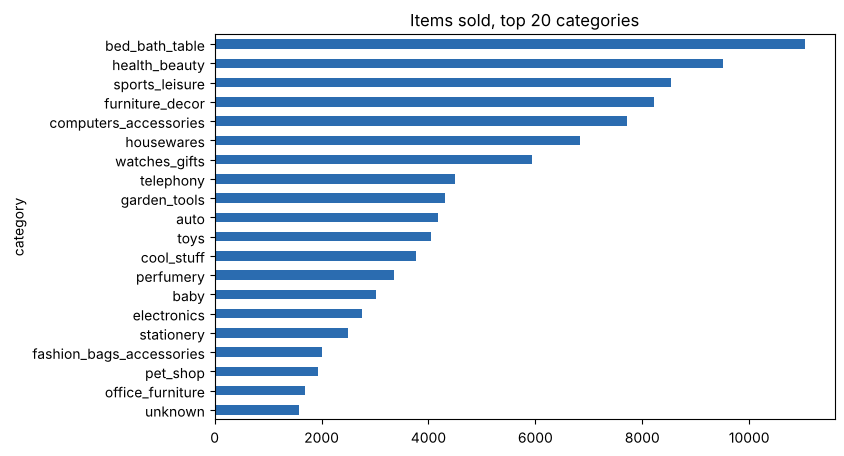

In [3]:
items = load_items(cfg["data"]["raw_dir"], cfg["data"]["start_date"], cfg["data"]["end_date"])
counts = items["category"].value_counts()
print(f"{len(counts)} categories, top 15 = {counts.head(15).sum() / counts.sum():.0%} of items")

fig, ax = plt.subplots(figsize=(8, 5))
counts.head(20)[::-1].plot.barh(ax=ax, color="#2b6cb0")
ax.set_title("Items sold, top 20 categories")
plt.show()

In [4]:
dow = items.groupby(items["date"].dt.dayofweek).size()
dow = dow / dow.mean()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow.round(2)

Mon    1.14
Tue    1.14
Wed    1.10
Thu    1.04
Fri    1.00
Sat    0.76
Sun    0.83
dtype: float64

Strong weekly pattern: Monday sells about 50% more than Saturday. Any forecast has to know the weekday.

In [5]:
weekly = weekly_listing_panel(items)
per_listing = weekly.groupby("listing").agg(weeks=("week", "size"), units=("units", "sum"),
                                            price_cv=("price", lambda p: p.std() / p.mean()))
print(f"{len(per_listing):,} listings")
print(f"sold in only one week: {(per_listing['weeks'] == 1).mean():.0%}")
print(f"sold in 8+ weeks:      {(per_listing['weeks'] >= 8).sum():,}")
long_lived = per_listing[per_listing["weeks"] >= 8]
print(f"...and of those, price moved by more than 2% (CV): {(long_lived['price_cv'] > 0.02).mean():.0%}")

33,884 listings
sold in only one week: 62%
sold in 8+ weeks:      1,595
...and of those, price moved by more than 2% (CV): 62%


Most listings sell once or twice, so they say nothing about price response. About a thousand
listings sold in 8+ weeks *and* changed price; that's the sample for the elasticity model.

In [6]:
# for those listings: how many weeks between the first and the last sale had no sales at all?
sample = long_lived[long_lived["price_cv"] > 0.02].index
w = weekly[weekly["listing"].isin(sample)]
span = w.groupby("listing")["week"].agg(lambda s: (s.max() - s.min()).days // 7 + 1)
active = w.groupby("listing").size()
print(f"share of weeks with zero sales inside a listing's active period: {1 - active.sum() / span.sum():.0%}")

share of weeks with zero sales inside a listing's active period: 66%


Two thirds of the weeks have **zero** sales. A log-log regression can't use them (log 0), and
dropping them removes the weeks where a high price meant nobody bought. That's why the elasticity
model is a Poisson regression that keeps the zeros (`pricing/elasticity.py`).

In [7]:
start = pd.Timestamp("2018-06-01")
pre = items[(items["date"] >= start - pd.Timedelta(weeks=16)) & (items["date"] < start)]
for unit in ["customer_city", "zip3"]:
    rev = pre.groupby(unit)["price"].sum().sort_values(ascending=False)
    orders = pre.groupby(unit)["order_id"].nunique()
    print(f"{unit:14s} units with >=10 orders: {(orders >= 10).sum():4d} | "
          f"biggest unit = {rev.iloc[0] / rev.sum():.1%} of revenue ({rev.index[0]})")

customer_city  units with >=10 orders:  342 | biggest unit = 15.4% of revenue (sao paulo)
zip3           units with >=10 orders:  578 | biggest unit = 1.4% of revenue (130)


For a geo experiment, cities are a bad unit: Sao Paulo alone is ~15% of revenue, so the
result would depend on which side Sao Paulo lands. 3-digit zip prefixes give several hundred
units and no single one dominates.